In [1]:
import torch 
import torch.nn as nn
import torchvision 
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

import torch.backends
import torch.backends.mps

import torch.utils
import torch.utils.data

from torch.optim.lr_scheduler import StepLR
from torch.utils.tensorboard import SummaryWriter
import copy
import random
import os

In [2]:
# device config
if torch.backends.mps.is_available(): 
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else: 
    device = torch.device("cpu")

device

device(type='mps')

In [3]:
# data already in range 0 - 1, no significant lighting changes, no need for distribution normalization
simple_transform = transforms.Compose([
    # transforms.ToTensor(),
])

complex_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomResizedCrop(size=(28, 28), scale=(0.8, 1.0), ratio=(3./4., 4./3.)),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.4),
    # transforms.ToTensor(), // already as tensor in the tum dataset
])

In [4]:
# load tum datasets
from torch.utils.data import Dataset, DataLoader

class CustomDataset(Dataset):
    def __init__(self, data_path, labels_path, transform):
        self.data = torch.load(data_path)
        self.labels = torch.load(labels_path)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]
        label = self.labels[idx]

        if self.transform: 
            image = self.transform(image)

        return image, label

# standard datasets
train_dataset = CustomDataset('./data/mnist/train_images.pt', './data/mnist/train_labels.pt', simple_transform)
test_dataset = CustomDataset('./data/mnist/test_images.pt', './data/mnist/test_labels.pt', simple_transform)
val_dataset = CustomDataset('./data/mnist/val_images.pt', './data/mnist/val_labels.pt', simple_transform)

# augment the training
augmented_train_dataset = CustomDataset('./data/mnist/train_images.pt', './data/mnist/train_labels.pt', complex_transform)

# augment directly
unlabeled_train_dataset = CustomDataset('./data/mnist/unlabeled_train_images.pt', './data/mnist/unlabeled_train_images.pt', complex_transform)

# no augmentation for validation
unlabeled_val_dataset = CustomDataset('./data/mnist/unlabeled_val_images.pt', './data/mnist/unlabeled_val_images.pt', simple_transform)

In [5]:
# check transforms 
print("Train size: ", len(train_dataset))
print("Val size: ", len(val_dataset))
print("Test size: ", len(test_dataset))

print("Unlabeled train size: ", len(unlabeled_train_dataset))
print("Unlabeled val size: ", len(unlabeled_val_dataset))

Train size:  100
Val size:  100
Test size:  100
Unlabeled train size:  58600
Unlabeled val size:  1000


In [ ]:
# ### loading from local 
# full_dataset_simple = torchvision.datasets.MNIST(root="data")

# # 0.8, 0.1, 0.1 split
# val_and_test_size = int(0.1 * len(full_dataset_simple))
# train_size = len(full_dataset_simple) - 2 * val_and_test_size

# train_dataset, test_dataset, val_dataset = torch.utils.data.random_split(full_dataset_simple, [train_size, val_and_test_size, val_and_test_size])
# augmented_train = copy.deepcopy(train_dataset)

# # add transforms 
# train_dataset.dataset.transform = simple_transform # will apply to test/val too
# augmented_train.dataset.transform = complex_transform

# # check transforms 
# print("Simple transform: ", train_dataset.dataset.transform)
# print("Complex transform: ", augmented_train.dataset.transform)

# total = len(train_dataset) + len(test_dataset) + len(val_dataset)

# print("Len of train_dataset: ", len(train_dataset))
# print("Len of test_dataset: ", len(test_dataset))
# print("Len of val_dataset: ", len(val_dataset))

# print(f"Percentage splits of train, test, val: {len(train_dataset)/total*100:.2f}%, {len(test_dataset)/total*100:.2f}%, {len(val_dataset)/total*100:.2f}%")

In [6]:
# get close to true distribution with large batch
batch_size = 1024

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)
val_loader = torch.utils.data.DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)

augmented_train_loader = torch.utils.data.DataLoader(dataset=augmented_train_dataset, batch_size=batch_size, shuffle=True)

unlabeled_train_loader = torch.utils.data.DataLoader(dataset=unlabeled_train_dataset, batch_size=batch_size, shuffle=True)
unlabeled_val_loader = torch.utils.data.DataLoader(dataset=unlabeled_val_dataset, batch_size=batch_size, shuffle=True)

In [7]:
examples = iter(train_loader) 

samples, labels = examples._next_data()

# samples shape: [batch_size, channels, height, width]
# labels: 0 - 9
samples.shape, labels.shape

(torch.Size([100, 1, 28, 28]), torch.Size([100]))

In [8]:
# single image, 1 channel x 28 height x 28 width
samples[0], samples[0].shape

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 

In [9]:
# single (and the only) channel, 28 x 28
samples[0][0]

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000

In [10]:
# single value correspoding to class label 0 - 9
labels[0]

tensor(7)

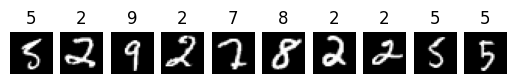

In [13]:
# plt.rcParams['figure.figsize'] = (16,16)

for j in range(10): 
    idx = random.randint(0, 99)
    image = samples[idx]

    main_channel = image[0, :, :]
    label = labels[idx].item()

    plt.subplot(1, 10, j+1)
    # Plotting Red Channel
    std = main_channel.std().item()
    mean = main_channel.mean().item()

    plt.imshow(main_channel, cmap='gray', )
    plt.title(f"{label}")
    plt.axis('off')  # Hide axes
plt.show()

In [14]:
# calculate mean and std of each channel
# here there is only one channel - grayscale
mean = torch.tensor(data=(0.0, ))
std = torch.tensor(data=(0.0, ))

for images, _ in train_loader:
    mean += torch.mean(images, dim=(0, 2, 3))
    std += torch.std(images, dim=(0, 2, 3))

mean = mean / len(train_loader)
std = std / len(train_loader)

# after transform here will be 0 mean and 1 std
mean, std

(tensor([0.1312]), tensor([0.3089]))

In [15]:
# remove tensorboard logs if it exists
!rm -rf runs

tf_iter = 0

In [16]:
class Autoencoder(nn.Module): 
    def __init__(self): 
        super(Autoencoder, self).__init__()

        # encoder part 
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128), 
            nn.BatchNorm1d(128),
            nn.LeakyReLU(negative_slope=0.01),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(negative_slope=0.01),

            nn.Linear(64, 32),
        )

        # decode the 32 features back to 28 x 28 image
        self.decoder = nn.Sequential(
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(negative_slope=0.01),

            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(negative_slope=0.01),

            nn.Linear(128, 28 * 28),

            # limits to original 0 - 1 range 
            nn.Sigmoid()
        )

    def forward(self, x): 
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [17]:
model = Autoencoder().to(device)

In [18]:
torch.save(model.state_dict(), './models/model_state_dict_intermediate.pth')

# check model params
n_params = sum(p.numel() for p in model.parameters())
print("Number of params (< 5M) ", n_params / 1e6) # < 5_000_000

size = os.path.getsize('./models/model_state_dict_intermediate.pth') # < 20MB
print("MB size: (< 20 MB) ", size / 1e6)

Number of params (< 5M)  0.223152
MB size: (< 20 MB)  0.906574


In [19]:
# start tensorboard
tf_iter += 1
writer = SummaryWriter(f'runs/mnist_autoen_{tf_iter}')

augmented_epochs = 30
normal_epochs = 15

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = StepLR(optimizer, step_size=1, gamma=0.99)

training_step = 0 
epoch_step = 0 

# using different dataloaders (augmented and normal)
def train_model(train_dataloader, val_dataloader, epochs):
    global training_step 
    global epoch_step 
    
    for epoch in range(epochs): 
        # put in train mode (batch norm)
        model.train()

        training_loss = 0

        for i, (images, _) in enumerate(train_dataloader): 
            images = images.view(images.size(0), -1) # flatten
            images = images.to(device) 

            outputs = model(images) 
            loss = criterion(outputs, images) 
            training_loss += loss.item()

            loss.backward()
            optimizer.step()
            optimizer.zero_grad()


        epoch_step += 1

        # current training loss, tracking for tensorboard
        writer.add_scalar('training loss', training_loss, epoch_step)
        
        # drop learning rate
        scheduler.step()
        writer.add_scalar('learning rate', scheduler.get_last_lr()[0], epoch_step)

        if epoch % 5 == 0: 
            torch.save(model.state_dict(), './models/model_state_dict_intermediate.pth')

        model.eval()

        # validation 
        with torch.no_grad(): 
            val_loss = 0

            for images, _ in val_dataloader: 
                images = images.view(images.size(0), -1)
                images = images.to(device)
                
                outputs = model(images)

                loss = criterion(outputs, images)
                val_loss += loss.item()

            writer.add_scalar('validation loss', val_loss, epoch_step)
            print(f"Epoch {epoch+1}/{epochs}, Val Loss: {val_loss:.4f}")

train_model(unlabeled_train_loader, unlabeled_val_loader, augmented_epochs)

# # # increase lr decay for fitting
# scheduler = StepLR(optimizer, step_size=1, gamma=0.95)

# train_model(train_loader, normal_epochs)


Epoch 1/30, Val Loss: 0.0553
Epoch 2/30, Val Loss: 0.0410
Epoch 3/30, Val Loss: 0.0344
Epoch 4/30, Val Loss: 0.0300
Epoch 5/30, Val Loss: 0.0272
Epoch 6/30, Val Loss: 0.0252
Epoch 7/30, Val Loss: 0.0235
Epoch 8/30, Val Loss: 0.0221
Epoch 9/30, Val Loss: 0.0210
Epoch 10/30, Val Loss: 0.0200
Epoch 11/30, Val Loss: 0.0194
Epoch 12/30, Val Loss: 0.0186
Epoch 13/30, Val Loss: 0.0181
Epoch 14/30, Val Loss: 0.0174
Epoch 15/30, Val Loss: 0.0170
Epoch 16/30, Val Loss: 0.0167
Epoch 17/30, Val Loss: 0.0163
Epoch 18/30, Val Loss: 0.0158
Epoch 19/30, Val Loss: 0.0155
Epoch 20/30, Val Loss: 0.0151
Epoch 21/30, Val Loss: 0.0150
Epoch 22/30, Val Loss: 0.0147
Epoch 23/30, Val Loss: 0.0145
Epoch 24/30, Val Loss: 0.0142
Epoch 25/30, Val Loss: 0.0140
Epoch 26/30, Val Loss: 0.0138
Epoch 27/30, Val Loss: 0.0137
Epoch 28/30, Val Loss: 0.0135
Epoch 29/30, Val Loss: 0.0134
Epoch 30/30, Val Loss: 0.0132


In [20]:
torch.save(model.state_dict(), './models/autoenc_state_dict.pth')

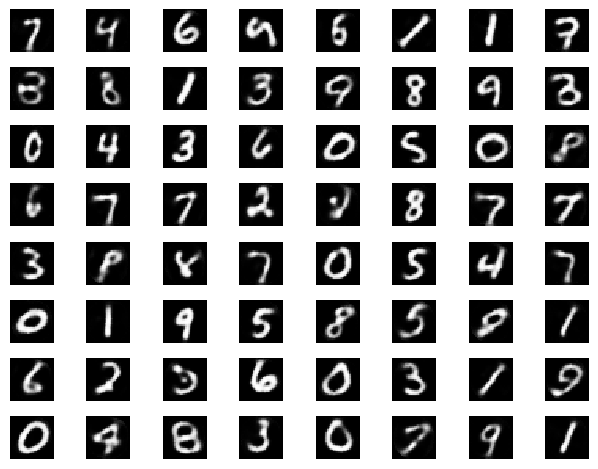

In [21]:
# check restauration images
model.to(device) 
model.eval()

with torch.no_grad():
    for i, batch in enumerate(unlabeled_val_loader): 
        images, labels = batch

        images = images.view(images.shape[0], -1)
        images = images.to(device)

        outputs = model(images)
        reconstructions = outputs.view(images.size(0), 1, 28, 28).cpu().detach().numpy()

        for i in range(64): 
            r = reconstructions[i]
            plt.subplot(8,8,i+1)
            plt.axis('off')
            plt.imshow(r[0], cmap='gray', interpolation='none')   

        break

plt.tight_layout()

In [26]:
# freeze encoder part
def freeze_model(model): 
    for param in model.parameters(): 
        param.requires_grad = False

freeze_model(model.encoder)

In [43]:
# classifier model 
class Classifier(nn.Module): 
    def __init__(self, encoder, encoded_features, num_classes): 
        super(Classifier, self).__init__()
        self.encoder = encoder

        self.classifier = nn.Sequential(
            nn.Linear(encoded_features, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.Linear(256, num_classes),
        )

    def forward(self, x): 
        x = self.encoder(x)
        x = self.classifier(x)
        return x
    

classifier = Classifier(encoder=model.encoder, encoded_features=32, num_classes=10).to(device)

In [69]:
# start tensorboard
tf_iter += 1
writer = SummaryWriter(f'runs/mnist_classify_{tf_iter}')

augmented_epochs = 300000
normal_epochs = 15

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=5e-4)
scheduler = StepLR(optimizer, step_size=1, gamma=1)

training_step = 0 
epoch_step = 0 

best_acc = 0

# using different dataloaders (augmented and normal)
def train_model(train_loader, val_loader, epochs):
    global training_step 
    global epoch_step 
    global best_acc
    
    for epoch in range(epochs): 
        classifier.train()

        training_acc = 0 

        for i, (images, labels) in enumerate(train_loader): 
            images = images.view(images.size(0), -1) # flatten

            images = images.to(device) 
            labels = labels.to(device) 

            outputs = classifier(images) 
            loss = criterion(outputs, labels) 

            training_acc += (outputs.argmax(dim=1) == labels).sum().item()

            optimizer.zero_grad()
            loss.backward()

            optimizer.step()

            # current training step, tracking for tensorboard
            training_step += 1
            writer.add_scalar('training loss', loss.item(), training_step)

            # if i % 100 == 0: 
            #     print(f"Epoch {epoch+1}/{epochs}, Step {i}/{len(train_loader)}, Loss: {loss.item():.4f}")

        epoch_step += 1

        training_acc /= len(train_dataset)
        writer.add_scalar('training accuracy', training_acc, epoch_step)
        
        # drop learning rate
        scheduler.step()
        writer.add_scalar('learning rate', scheduler.get_last_lr()[0], epoch_step)

        if epoch % 5 == 0: 
            torch.save(classifier.state_dict(), './model_state_dict_intermediate.pth')

        classifier.eval()
        
        # validation 
        with torch.no_grad(): 
            n_correct = 0
            n_samples = 0

            for images, labels in val_loader: 
                images = images.view(images.size(0), -1)

                images = images.to(device)
                labels = labels.to(device)
                
                outputs = classifier(images)

                _, predicted = torch.max(outputs, 1)
                n_samples += labels.size(0)
                n_correct += (predicted == labels).sum().item()

            acc = 100.0 * n_correct / n_samples
            writer.add_scalar('validation accuracy', acc, epoch_step)
            print(f"Epoch {epoch+1}/{epochs}, Val Loss: {loss.item():.4f}, Accuracy: {acc:.2f}")

            if acc > best_acc: 
                best_acc = acc
                torch.save(classifier.state_dict(), './models/classify_state_dict.pth')
                print(f"Best model saved with accuracy: {best_acc:.2f}")

train_model(augmented_train_loader, val_loader, augmented_epochs)

# # increase lr decay for fitting
# scheduler = StepLR(optimizer, step_size=1, gamma=0.95)

# train_model(train_loader, val_loader, normal_epochs)


Epoch 1/300000, Val Loss: 0.0568, Accuracy: 81.00
Best model saved with accuracy: 81.00
Epoch 2/300000, Val Loss: 0.0080, Accuracy: 81.00
Epoch 3/300000, Val Loss: 0.0073, Accuracy: 82.00
Best model saved with accuracy: 82.00
Epoch 4/300000, Val Loss: 0.0230, Accuracy: 82.00
Epoch 5/300000, Val Loss: 0.0191, Accuracy: 81.00
Epoch 6/300000, Val Loss: 0.0127, Accuracy: 81.00
Epoch 7/300000, Val Loss: 0.0047, Accuracy: 81.00
Epoch 8/300000, Val Loss: 0.0412, Accuracy: 81.00
Epoch 9/300000, Val Loss: 0.0039, Accuracy: 81.00
Epoch 10/300000, Val Loss: 0.0127, Accuracy: 81.00
Epoch 11/300000, Val Loss: 0.0011, Accuracy: 81.00
Epoch 12/300000, Val Loss: 0.0589, Accuracy: 80.00
Epoch 13/300000, Val Loss: 0.0072, Accuracy: 80.00
Epoch 14/300000, Val Loss: 0.0095, Accuracy: 81.00
Epoch 15/300000, Val Loss: 0.0352, Accuracy: 81.00
Epoch 16/300000, Val Loss: 0.0172, Accuracy: 81.00
Epoch 17/300000, Val Loss: 0.0153, Accuracy: 81.00
Epoch 18/300000, Val Loss: 0.0350, Accuracy: 81.00
Epoch 19/300000

KeyboardInterrupt: 

In [66]:
# how to load
autoencoder = Autoencoder()
classifier = Classifier(encoder=autoencoder.encoder, encoded_features=32, num_classes=10)

classifier.load_state_dict(torch.load('./models/classify_state_dict.pth', map_location=device))

<All keys matched successfully>

In [68]:
# test accuracy, single shot
classifier.to(device)
classifier.eval()

with torch.no_grad():
    n_correct = 0
    n_samples = 0

    for images, labels in test_loader: 
        images = images.view(images.size(0), -1)

        images = images.to(device)
        labels = labels.to(device)

        outputs = classifier(images)

        _, predicted = torch.max(outputs, 1)
        n_samples += labels.size(0)
        n_correct += (predicted == labels).sum().item()

    acc = 100.0 * n_correct / n_samples
    print(f"Test Accuracy: {acc:.2f}")

Test Accuracy: 83.00
